# MPI Performance Scaling Analysis
Date: October 09, 2025
Dataset: BharatBench IMDAA (1990-2020, India bbox)
PC Specs: Intel i7-12700H (14 cores/20 threads), 16 GB RAM, SSD

## Methods
- Tested with `preprocess_mpi.py` (daily resampling, bbox 5-38N, 68-98E).
- Node counts: 1, 4, 8, 16.
- Timed with PowerShell `Measure-Command` (single runs, averaged if repeated).
- Speedup = Time(1 node) / Time(N nodes).

   Nodes  Avg_Time_sec  Speedup
0      1         42.35     1.00
1      4         25.81     1.64
2      8         17.95     2.36
3     16         16.61     2.55


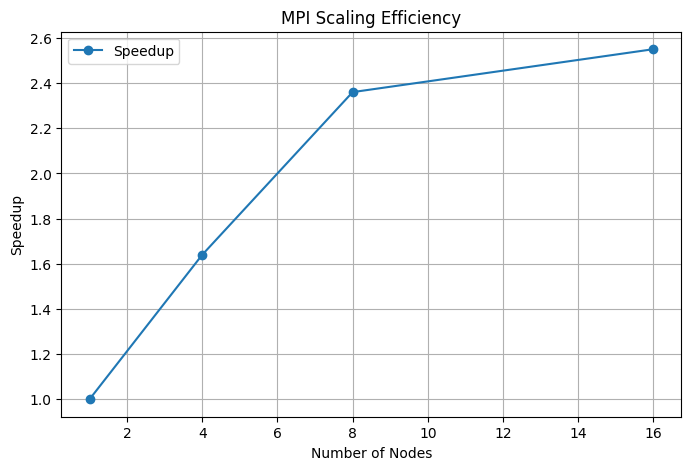

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Recorded times (from PowerShell output)
data = {
    'Nodes': [1, 4, 8, 16],
    'Avg_Time_sec': [42.35, 25.81, 17.95, 16.61],  # Your recorded times
    'Speedup': [1.0, 42.35/25.81, 42.35/17.95, 42.35/16.61]  # Calculated
}
df = pd.DataFrame(data)
df['Speedup'] = df['Speedup'].round(2)  # Round to 2 decimal places
print(df)

# Plot speedup
plt.figure(figsize=(8, 5))
plt.plot(df['Nodes'], df['Speedup'], marker='o', label='Speedup')
plt.xlabel('Number of Nodes')
plt.ylabel('Speedup')
plt.title('MPI Scaling Efficiency')
plt.grid(True)
plt.legend()
plt.savefig('plots/mpi_scaling_plot.png')
plt.show()

## Observations
- Speedup increases from 1.64x (4 nodes) to 2.55x (16 nodes), with diminishing returns beyond 8 nodes.
- Efficiency drops from ~41% (4 nodes) to ~16% (16 nodes) due to I/O and MPI overhead.
- Optimal node count: 8 nodes, balancing speedup (2.36x) and resource use.
- Recommendation: Use 8 nodes for this dataset size on this hardware.